<div style="background: linear-gradient(135deg, #6E4B9F 0%, #35BEAE 100%); border-radius: 14px; padding: 28px 32px; margin-bottom: 10px;">
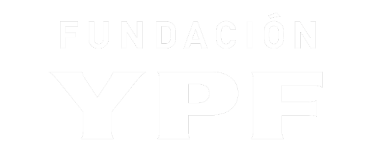
<h2 style="color: #FFFFFF; margin-top: 18px; margin-bottom: 0; font-family: sans-serif;">Fundacion YPF | Data Science</h2>
</div>

# Notebook 18: Practica de Regresion y Clasificacion

**Clase 14**

## Indice

- **Parte 0**: Introduccion y objetivos
- **Parte 1**: Regresion, prediccion del precio de autos usados
- **Parte 2**: Clasificacion, prediccion de recurrencia de cancer de mama
- **Parte 3**: Desafio para las salas


## Parte 0: Introduccion y objetivos

En la Clase 12 y en la Clase 13 vimos los algoritmos mas comunes de regresion y clasificacion: Regresion Lineal, Arboles de Decision, Random Forest, Regresion Logistica, K Nearest Neighbors (KNN) y Support Vector Machine (SVM).

En esta notebook practicamos el ajuste de esos modelos de punta a punta, repasando lo trabajado en las Notebooks 16 y 17: cargar los datos, explorarlos, limpiarlos, prepararlos para el modelo, ajustar varios algoritmos y comparar sus resultados.

Vamos a trabajar con dos datasets distintos:

- **Regresion**: un dataset de venta de autos usados, donde el objetivo es predecir el precio de venta.
- **Clasificacion**: el dataset de cancer de mama que ya usamos en las clases anteriores, donde el objetivo es predecir si hubo recurrencia de la enfermedad.

Empecemos importando las librerias que vamos a necesitar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

pd.set_option('display.max_columns', None)


## Parte 1: Regresion, prediccion del precio de autos usados

Vamos a trabajar con un dataset de publicaciones de venta de autos usados. El objetivo es predecir el **precio de venta** (`price`) a partir de las caracteristicas del vehiculo, como el tipo de carroceria, el anio de registro, la potencia, el kilometraje, la marca, entre otras.

Este es un dataset real, asi que va a tener valores faltantes y errores de carga que vamos a tener que limpiar antes de poder entrenar un modelo.

### 1.1 Carga y exploracion de datos

In [2]:
df_autos = pd.read_csv('venta_autos.csv', encoding='latin1')
df_autos.head(50)


,dateCrawled,name,seller,offerType,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,kilometer,monthOfRegistration,fuelType,brand,notRepairedDamage,dateCreated,postalCode,lastSeen
0,30/03/2016 13:51,Zu_verkaufen,private,offer,4450,test,limousine,2003,manual,150,3er,150000,3,diesel,bmw,NaN,30/03/2016 0:00,20257,7/4/2016 4:44
1,7/3/2016 9:54,Volvo_XC90_2.4D_Summum,private,offer,13299,control,suv,2005,manual,163,xc_reihe,150000,6,diesel,volvo,no,7/3/2016 0:00,88045,26/03/2016 13:17
2,1/4/2016 0:57,Volkswagen_Touran,private,offer,3200,test,bus,2003,manual,101,touran,150000,11,diesel,volkswagen,NaN,31/03/2016 0:00,27449,1/4/2016 8:40
3,19/03/2016 17:50,Seat_Ibiza_1.4_16V_Reference,private,offer,4500,control,small car,2006,manual,86,ibiza,60000,12,petrol,seat,no,19/03/2016 0:00,34537,7/4/2016 4:44
4,16/03/2016 14:51,Volvo_XC90_D5_Aut._RDesign_R_Design_AWD_GSHD_S...,private,offer,18750,test,suv,2008,automatic,185,xc_reihe,150000,11,diesel,volvo,no,16/03/2016 0:00,55270,1/4/2016 23:18
5,2/4/2016 12:51,VW_Passat_35i_Facelift_Limousine_TÃV_Neu,private,offer,988,test,limousine,1995,manual,90,passat,150000,2,petrol,volkswagen,no,2/4/2016 0:00,26826,2/4/2016 12:51
6,3/4/2016 11:06,Opel_astra,private,offer,400,test,station wagon,1996,manual,0,astra,150000,5,petrol,opel,NaN,3/4/2016 0:00,56422,6/4/2016 16:47
7,24/03/2016 15:52,Mercedes_Benz_CLK_Coupe_200,private,offer,1399,test,coupe,1997,manual,136,clk,150000,11,petrol,mercedes_benz,no,24/03/2016 0:00,13353,27/03/2016 12:45
8,28/03/2016 14:40,Vectra_C_Caravan_1_8_Edition_Facelift_m_AHK_In...,private,offer,4680,test,station wagon,2005,manual,122,vectra,150000,12,petrol,opel,no,28/03/2016 0:00,28307,6/4/2016 18:19
9,5/4/2016 11:38,Skoda_Octavia_2.0_TDI_DSG_Elegance,private,offer,8340,test,limousine,2005,automatic,140,octavia,125000,4,diesel,skoda,no,5/4/2016 0:00,16761,5/4/2016 11:38


In [5]:
df_autos.shape

(50001, 19)

In [4]:
df_autos.info()


<class 'pandas.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   dateCrawled          50001 non-null  str  
 1   name                 50001 non-null  str  
 2   seller               50001 non-null  str  
 3   offerType            50001 non-null  str  
 4   price                50001 non-null  int64
 5   abtest               50001 non-null  str  
 6   vehicleType          44813 non-null  str  
 7   yearOfRegistration   50001 non-null  int64
 8   gearbox              47177 non-null  str  
 9   powerPS              50001 non-null  int64
 10  model                47243 non-null  str  
 11  kilometer            50001 non-null  int64
 12  monthOfRegistration  50001 non-null  int64
 13  fuelType             45498 non-null  str  
 14  brand                50001 non-null  str  
 15  notRepairedDamage    40285 non-null  str  
 16  dateCreated          50001 non-nu

Miremos con mas detalle las columnas numericas que vamos a usar como predictoras y como variable objetivo. Prestale atencion al minimo y al maximo de cada una: ¿te parecen valores razonables para un auto usado?

In [6]:
df_autos[['price', 'yearOfRegistration', 'powerPS', 'kilometer']].describe()


,price,yearOfRegistration,powerPS,kilometer
count,5.000100e+04,50001.000000,50001.000000,50001.000000
mean,6.559865e+03,2005.544229,116.496130,125613.687726
std,8.581847e+04,122.991832,230.567709,40205.234483
min,0.000000e+00,1000.000000,0.000000,5000.000000
25%,1.150000e+03,1999.000000,69.000000,125000.000000
50%,2.950000e+03,2003.000000,105.000000,150000.000000
75%,7.190000e+03,2008.000000,150.000000,150000.000000
max,1.234568e+07,9999.000000,19312.000000,150000.000000


Como te habras dado cuenta, hay valores que no tienen sentido: autos con `price` en 0, anios de registro como 1000 o 9999, y potencias (`powerPS`) en 0 o en varios miles de caballos de fuerza. Antes de entrenar cualquier modelo, tenemos que limpiar estos datos.

### 1.2 Limpieza de datos

Vamos a quedarnos solo con los datos que tienen valores razonables:

- `price` entre 500 y 100.000
- `yearOfRegistration` entre 1950 y 2016 (el dataset fue relevado en 2016)
- `powerPS` entre 40 y 600 caballos de fuerza

Ademas, hay columnas categoricas con valores faltantes (`vehicleType`, `gearbox`, `fuelType`, `notRepairedDamage`). En vez de eliminar esas filas, las vamos a completar con la categoria `"desconocido"`, para no perder informacion de las demas columnas.

In [7]:
#Filtramos los valores fuera de rango en price, yearOfRegistration y powerPS
df_autos = df_autos[(df_autos['price'] >= 500) & (df_autos['price'] <= 100000)]
df_autos = df_autos[(df_autos['yearOfRegistration'] >= 1950) & (df_autos['yearOfRegistration'] <= 2016)]
df_autos = df_autos[(df_autos['powerPS'] >= 40) & (df_autos['powerPS'] <= 600)]

print('Filas luego de filtrar valores fuera de rango:', df_autos.shape[0])


Filas luego de filtrar valores fuera de rango: 39604


In [9]:
#Completamos los valores faltantes de las columnas categoricas con "desconocido"
columnas_categoricas = ['vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

for columna in columnas_categoricas:
    df_autos[columna] = df_autos[columna].fillna('desconocido')

df_autos[columnas_categoricas].isna().sum()


vehicleType          0
gearbox              0
fuelType             0
notRepairedDamage    0
dtype: int64

### 1.3 Seleccion de variables y codificacion

Nos quedamos solo con las columnas que le van a aportar informacion util al modelo. Descartamos columnas como `dateCrawled`, `name`, `seller`, `offerType`, `abtest`, `model`, `dateCreated`, `postalCode` y `lastSeen`, que no describen al vehiculo en si o que tienen demasiadas categorias distintas para esta primera aproximacion.

Los modelos de Machine Learning necesitan que todas las variables sean numericas, asi que las columnas categoricas (`vehicleType`, `gearbox`, `fuelType`, `brand`, `notRepairedDamage`) las transformamos con **one-hot encoding**, usando `pd.get_dummies`.

In [10]:
columnas_a_usar = ['price', 'vehicleType', 'yearOfRegistration', 'gearbox', 'powerPS',
                   'kilometer', 'monthOfRegistration', 'fuelType', 'brand', 'notRepairedDamage']

df_autos_modelo = df_autos[columnas_a_usar].copy()

df_autos_encoded = pd.get_dummies(df_autos_modelo,
                                   columns=['vehicleType', 'gearbox', 'fuelType', 'brand', 'notRepairedDamage'],
                                   drop_first=True)

print('Forma del dataset luego de codificar:', df_autos_encoded.shape)
df_autos_encoded.head()


Forma del dataset luego de codificar: (39604, 63)


,price,yearOfRegistration,powerPS,kilometer,monthOfRegistration,vehicleType_cabrio,vehicleType_coupe,vehicleType_desconocido,vehicleType_limousine,vehicleType_others,vehicleType_small car,vehicleType_station wagon,vehicleType_suv,gearbox_desconocido,gearbox_manual,fuelType_desconocido,fuelType_diesel,fuelType_electro,fuelType_hybrid,fuelType_lpg,fuelType_other,fuelType_petrol,brand_audi,brand_bmw,brand_chevrolet,brand_chrysler,brand_citroen,brand_dacia,brand_daewoo,brand_daihatsu,brand_fiat,brand_ford,brand_honda,brand_hyundai,brand_jaguar,brand_jeep,brand_kia,brand_lada,brand_lancia,brand_land_rover,brand_mazda,brand_mercedes_benz,brand_mini,brand_mitsubishi,brand_nissan,brand_opel,brand_peugeot,brand_porsche,brand_renault,brand_rover,brand_saab,brand_seat,brand_skoda,brand_smart,brand_sonstige_autos,brand_subaru,brand_suzuki,brand_toyota,brand_trabant,brand_volkswagen,brand_volvo,notRepairedDamage_no,notRepairedDamage_yes
0,4450,2003,150,150000,3,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,13299,2005,163,150000,6,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False
2,3200,2003,101,150000,11,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,4500,2006,86,60000,12,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False
4,18750,2008,185,150000,11,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False


### 1.4 Division en train y test

Separamos las variables predictoras (`X`) de la variable objetivo (`y`), y dividimos el dataset en un conjunto de entrenamiento (80%) y uno de testeo (20%).

In [11]:
X_autos = df_autos_encoded.drop(columns=['price'])
y_autos = df_autos_encoded['price']

X_train_autos, X_test_autos, y_train_autos, y_test_autos = train_test_split(
    X_autos, y_autos, test_size=0.2, random_state=42
)

print('Train:', X_train_autos.shape)
print('Test:', X_test_autos.shape)


Train: (31683, 62)
Test: (7921, 62)


### 1.5 Ajuste de modelos de regresion

Ahora si, entrenamos tres modelos distintos sobre los mismos datos y comparamos como se comportan:

- **Regresion Lineal**
- **Arbol de Decision**
- **Random Forest**

In [13]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_autos, y_train_autos)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](62,)","[ 213.34, 54.42, -0.08,..., -188.9 , 771.41,-1245.88]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](62,)","['yearOfRegistration','powerPS','kilometer',...,'brand_volvo', 'notRepairedDamage_no','notRepairedDamage_yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.182e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,62
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(50)


In [14]:
modelo_arbol = DecisionTreeRegressor(max_depth=8, random_state=42)
modelo_arbol.fit(X_train_autos, y_train_autos)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [15]:
modelo_rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_autos, y_train_autos)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

### 1.6 Evaluacion y comparacion de modelos

Para comparar los tres modelos usamos tres metricas de regresion:

- **MAE** (Mean Absolute Error): el error promedio, en las mismas unidades que el precio.
- **RMSE** (Root Mean Squared Error): tambien en unidades de precio, pero penaliza mas fuerte los errores grandes.
- **R2**: que porcentaje de la variabilidad del precio explica el modelo (cuanto mas cerca de 1, mejor).

In [16]:
modelos_regresion = {
    'Regresion Lineal': modelo_lineal,
    'Arbol de Decision': modelo_arbol,
    'Random Forest': modelo_rf
}

resultados_regresion = []

for nombre, modelo in modelos_regresion.items():
    predicciones = modelo.predict(X_test_autos)
    mae = mean_absolute_error(y_test_autos, predicciones)
    rmse = mean_squared_error(y_test_autos, predicciones) ** 0.5
    r2 = r2_score(y_test_autos, predicciones)
    resultados_regresion.append({'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

df_resultados_regresion = pd.DataFrame(resultados_regresion)
df_resultados_regresion


,Modelo,MAE,RMSE,R2
0,Regresion Lineal,2881.057163,4609.014418,0.655328
1,Arbol de Decision,1948.219759,3677.829946,0.780531
2,Random Forest,1666.945940,3128.962890,0.841149


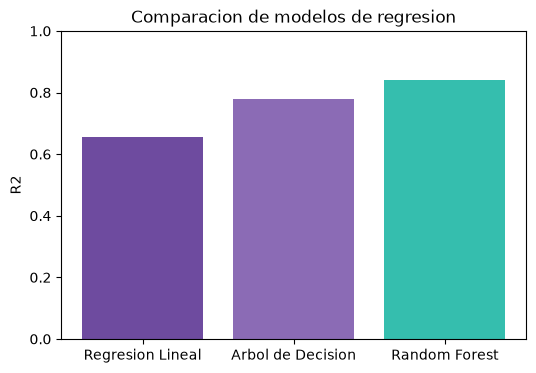

In [17]:
plt.figure(figsize=(6, 4))
plt.bar(df_resultados_regresion['Modelo'], df_resultados_regresion['R2'], color=['#6E4B9F', '#8B6BB5', '#35BEAE'])
plt.ylabel('R2')
plt.title('Comparacion de modelos de regresion')
plt.ylim(0, 1)
plt.show()


**Para pensar y discutir en el grupo:** ¿Cual de los tres modelos tuvo mejor desempenio? ¿Te parece razonable que el Random Forest le gane a un unico Arbol de Decision? ¿Que pasaria si le sumamos la columna `model`, con muchas mas categorias?

## Parte 2: Clasificacion, prediccion de recurrencia de cancer de mama

Volvemos a trabajar con el dataset `cancer_mamario.csv`, que ya usamos en las Notebooks 16 y 17. Esta vez el objetivo es armar el pipeline completo: desde la carga de los datos hasta la comparacion de varios modelos de clasificacion.

La variable objetivo es `class`, que indica si hubo o no recurrencia de la enfermedad (`recurrence-events` o `no-recurrence-events`).

### 2.1 Carga y exploracion de datos

In [18]:
df_cancer = pd.read_csv('cancer_mamario.csv')
df_cancer.head()


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [19]:
df_cancer['class'].value_counts()


class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64

Fijate que las clases no estan balanceadas: hay muchos mas casos de `no-recurrence-events` que de `recurrence-events`. Vamos a tenerlo en cuenta mas adelante, al elegir la division en train y test y al interpretar las metricas.

### 2.2 Limpieza de datos

En este dataset los valores faltantes no aparecen como `NaN`, sino como el caracter `"?"`. Antes de poder detectarlos con `isna()`, tenemos que reemplazarlos.

In [20]:
df_cancer = df_cancer.replace('?', np.nan)
df_cancer.isna().sum()


class          0
age            0
menopause      0
tumor-size     0
inv-nodes      0
node-caps      8
deg-malig      0
breast         0
breast-quad    1
irradiat       0
dtype: int64

Solo dos columnas tienen valores faltantes, y son pocos casos. En vez de eliminar esas filas, las completamos con la moda (el valor mas frecuente) de cada columna.

In [22]:
df_cancer['node-caps'] = df_cancer['node-caps'].fillna(df_cancer['node-caps'].mode()[0])
df_cancer['breast-quad'] = df_cancer['breast-quad'].fillna(df_cancer['breast-quad'].mode()[0])

df_cancer.isna().sum().sum()


np.int64(0)

### 2.3 Codificacion de variables y variable objetivo

Convertimos la variable objetivo en binaria (1 si hubo recurrencia, 0 si no), y codificamos las variables predictoras categoricas con `pd.get_dummies`, igual que hicimos en la Parte 1.

In [23]:
df_cancer['target'] = (df_cancer['class'] == 'recurrence-events').astype(int)
df_cancer = df_cancer.drop(columns=['class'])

columnas_categoricas_cancer = ['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps', 'breast', 'breast-quad', 'irradiat']

df_cancer_encoded = pd.get_dummies(df_cancer, columns=columnas_categoricas_cancer, drop_first=True)

print('Forma del dataset luego de codificar:', df_cancer_encoded.shape)
df_cancer_encoded.head()


Forma del dataset luego de codificar: (286, 32)


,deg-malig,target,age_30-39,age_40-49,age_50-59,age_60-69,age_70-79,menopause_lt40,menopause_premeno,tumor-size_10-14,tumor-size_15-19,tumor-size_20-24,tumor-size_25-29,tumor-size_30-34,tumor-size_35-39,tumor-size_40-44,tumor-size_45-49,tumor-size_5-9,tumor-size_50-54,inv-nodes_12-14,inv-nodes_15-17,inv-nodes_24-26,inv-nodes_3-5,inv-nodes_6-8,inv-nodes_9-11,node-caps_yes,breast_right,breast-quad_left_low,breast-quad_left_up,breast-quad_right_low,breast-quad_right_up,irradiat_yes
0,3,0,True,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,2,0,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False
2,2,0,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
3,2,0,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False
4,2,0,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False


### 2.4 Division en train, test y escalado

Usamos `stratify=y` para que la proporcion de recurrencia se mantenga parecida en train y en test, dado el desbalance de clases que vimos antes.

Ademas, KNN y SVM son modelos sensibles a la escala de las variables, asi que estandarizamos los datos con `StandardScaler` antes de entrenarlos.

In [25]:
X_cancer = df_cancer_encoded.drop(columns=['target'])
y_cancer = df_cancer_encoded['target']

X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(
    X_cancer, y_cancer, test_size=0.25, random_state=42, stratify=y_cancer
)

escalador = StandardScaler()
X_train_cancer_esc = escalador.fit_transform(X_train_cancer)
X_test_cancer_esc = escalador.transform(X_test_cancer)

print('Train:', X_train_cancer.shape)
print('Test:', X_test_cancer.shape)


Train: (214, 31)
Test: (72, 31)


### 2.5 Ajuste de modelos de clasificacion

Entrenamos tres modelos sobre los datos ya escalados:

- **Regresion Logistica**
- **K Nearest Neighbors** (con k=5)
- **Support Vector Machine** (con kernel RBF)

In [26]:
modelo_logistica = LogisticRegression(max_iter=1000)
modelo_logistica.fit(X_train_cancer_esc, y_train_cancer)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [27]:
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_cancer_esc, y_train_cancer)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [28]:
modelo_svm = SVC(kernel='rbf', random_state=42)
modelo_svm.fit(X_train_cancer_esc, y_train_cancer)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


### 2.6 Evaluacion y comparacion de modelos

Para clasificacion usamos otro grupo de metricas:

- **Accuracy**: proporcion total de aciertos.
- **Precision**: de los casos que el modelo predijo como recurrencia, cuantos lo eran realmente.
- **Recall**: de los casos que realmente eran recurrencia, cuantos detecto el modelo.
- **F1**: un promedio entre precision y recall.

En un problema desbalanceado como este, el accuracy solo no alcanza para saber si el modelo es bueno: hay que mirar tambien precision y recall.

In [32]:
modelos_clasificacion = {
    'Regresion Logistica': modelo_logistica,
    'KNN (k=5)': modelo_knn,
    'SVM (kernel rbf)': modelo_svm
}

resultados_clasificacion = []

for nombre, modelo in modelos_clasificacion.items():
    predicciones = modelo.predict(X_test_cancer_esc)
    accuracy = accuracy_score(y_test_cancer, predicciones)
    precision = precision_score(y_test_cancer, predicciones)
    recall = recall_score(y_test_cancer, predicciones)
    f1 = f1_score(y_test_cancer, predicciones)
    resultados_clasificacion.append({'Modelo': nombre, 'Accuracy': accuracy, 'Precision': precision,
                                      'Recall': recall, 'F1': f1})

df_resultados_clasificacion = pd.DataFrame(resultados_clasificacion)
df_resultados_clasificacion


,Modelo,Accuracy,Precision,Recall,F1
0,Regresion Logistica,0.638889,0.352941,0.285714,0.315789
1,KNN (k=5),0.694444,0.428571,0.142857,0.214286
2,SVM (kernel rbf),0.680556,0.400000,0.190476,0.258065


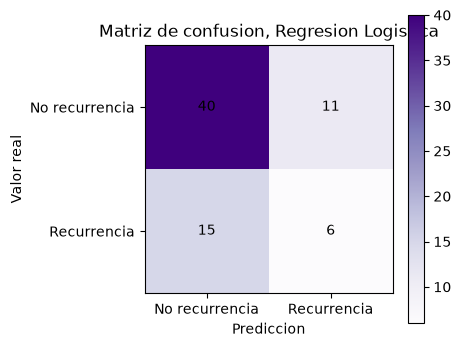

In [33]:
#Matriz de confusion del modelo de Regresion Logistica
predicciones_logistica = modelo_logistica.predict(X_test_cancer_esc)
matriz_confusion = confusion_matrix(y_test_cancer, predicciones_logistica)

plt.figure(figsize=(4, 4))
plt.imshow(matriz_confusion, cmap='Purples')
plt.title('Matriz de confusion, Regresion Logistica')
plt.xlabel('Prediccion')
plt.ylabel('Valor real')
plt.xticks([0, 1], ['No recurrencia', 'Recurrencia'])
plt.yticks([0, 1], ['No recurrencia', 'Recurrencia'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz_confusion[i, j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()


**Para pensar y discutir en el grupo:** ¿Cual modelo tuvo mejor recall para detectar la clase `recurrencia`? ¿Por que puede ser mas importante el recall que el accuracy en un problema como este? ¿Que otras variables del dataset original te parece que podrian ayudar a mejorar la deteccion?

## Parte 3: Desafio para las salas

Llego tu turno de poner en practica lo que vimos. Trabajando en tu grupo, completa el codigo de las celdas siguientes.

**Consigna 1 (Regresion):** Volve a entrenar el Random Forest de la Parte 1, pero probando con otro valor de `max_depth`. ¿Mejora o empeora el R2 en el conjunto de test?

In [ ]:
#Completa el codigo: entrena un nuevo Random Forest cambiando el valor de max_depth
#y calcula su R2 sobre X_test_autos / y_test_autos

modelo_rf_desafio = RandomForestRegressor(n_estimators=100, max_depth=..., random_state=42, n_jobs=-1)
modelo_rf_desafio.fit(X_train_autos, y_train_autos)

predicciones_desafio = modelo_rf_desafio.predict(X_test_autos)
r2_desafio = r2_score(y_test_autos, predicciones_desafio)
print('R2 con el nuevo max_depth:', r2_desafio)


R2 con el nuevo max_depth: 0.7654888335328771


**Consigna 2 (Clasificacion):** Entrena un Arbol de Decision para el problema de clasificacion del cancer de mama (usa `DecisionTreeClassifier`) y calcula su accuracy, precision, recall y F1 sobre el conjunto de test. ¿Como se compara contra los tres modelos que ya entrenamos?

In [ ]:
#Completa el codigo: importa DecisionTreeClassifier, entrenalo con
#X_train_cancer_esc / y_train_cancer y evalua sus metricas sobre el conjunto de test

from sklearn.tree import DecisionTreeClassifier

modelo_arbol_cancer = DecisionTreeClassifier(...)
modelo_arbol_cancer.fit(X_train_cancer_esc, y_train_cancer)

predicciones_arbol_cancer = modelo_arbol_cancer.predict(X_test_cancer_esc)

#Calcula e imprimi accuracy, precision, recall y F1


**Consigna 3:** Si tu grupo ya eligio el dataset para el proyecto final, empiecen a aplicar sobre el este mismo recorrido: cargar los datos, explorarlos, limpiarlos, codificar las variables categoricas, dividir en train y test, y ajustar una primera version de un modelo de regresion o de clasificacion, segun corresponda a su problema.